<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Vega_gamma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DELTA-GAMMA-VEGA HEDGING

INITIAL PORTFOLIO
---------------------------------------------
Target delta exposure: -5.908802
Target gamma exposure: -0.219795
Target vega exposure : -274.743217
90-strike hedge qty  : 2.971815
110-strike hedge qty : 8.000000
Stock hedge quantity : 0.516351

Simulated paths: (3000, 127)

HEDGING PERFORMANCE
                              Mean P&L   P&L Std Dev  Mean Absolute P&L  \
Delta Hedging            -8.889860e+01  5.652900e+00       8.889860e+01   
Delta-Gamma Hedging      -4.534070e+09  1.695555e+10       4.534070e+09   
Delta-Gamma-Vega Hedging -1.269223e+93  6.930082e+94       1.269223e+93   

                          Probability of Loss (%)  95% VaR (Loss)  \
Delta Hedging                               100.0    9.880250e+01   
Delta-Gamma Hedging                         100.0    2.835003e+10   
Delta-Gamma-Vega Hedging                    100.0    1.986035e+54   

                          95% Expected Shortfall  
Delta Hedging                    

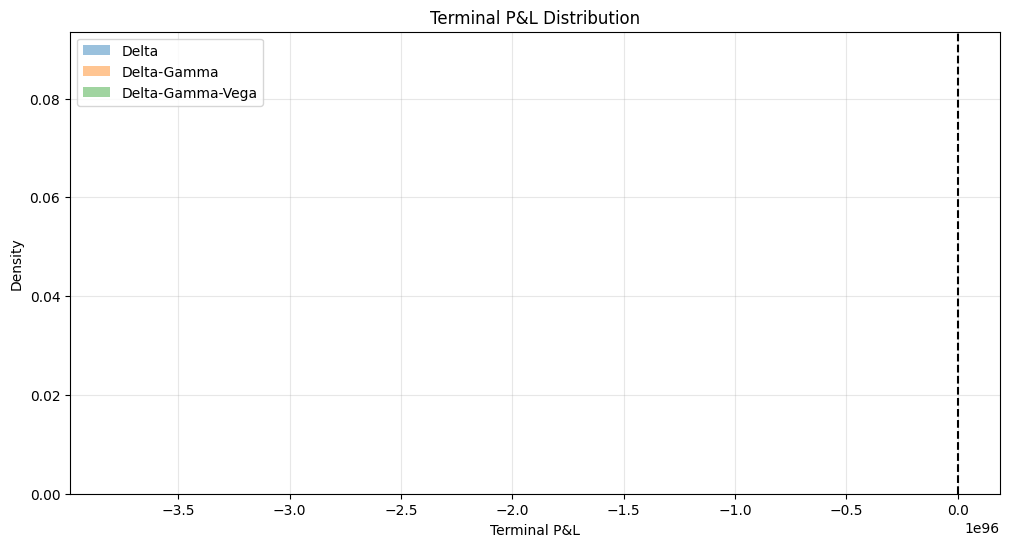


VOLATILITY STRESS TEST
   Volatility Shock  Volatility  Net Gamma  Net Vega
0             -0.10        0.15        NaN       NaN
1             -0.05        0.20        NaN       NaN
2              0.00        0.25        0.0       0.0
3              0.05        0.30        NaN       NaN
4              0.10        0.35        NaN       NaN


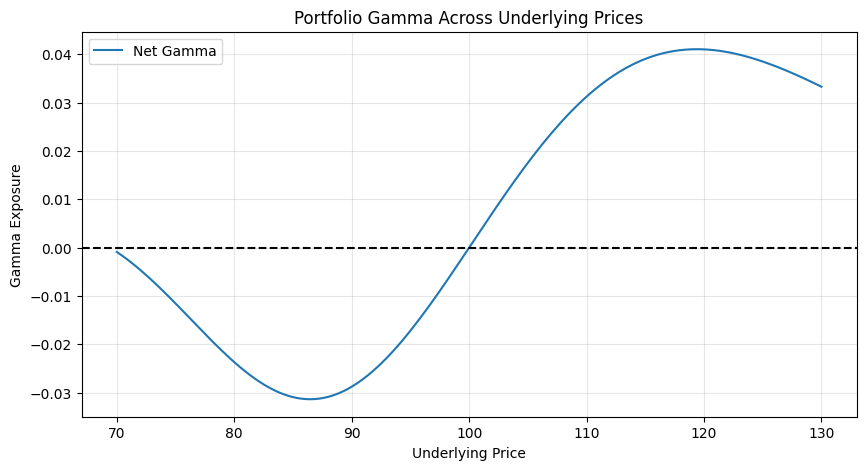

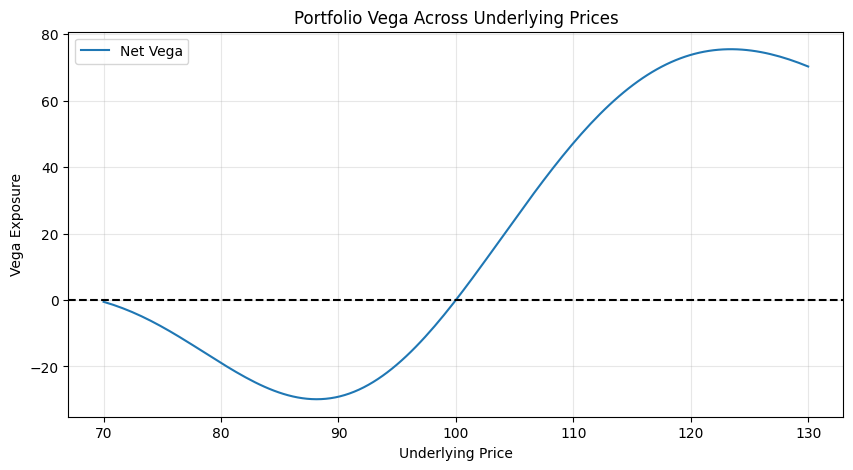


RESEARCH SUMMARY
1. Delta hedging controls first-order price exposure.
2. Gamma hedging targets second-order price exposure.
3. Vega hedging targets sensitivity to volatility.
4. Frequent rebalancing introduces additional transaction costs.
5. Hedge effectiveness depends on strikes and time to expiry.

NOTE: This is a theoretical simulation, not a live-market backtest.
The model assumes constant volatility and theoretical option prices.


In [ ]:

# ================================================================
# DELTA-GAMMA-VEGA HEDGING
# Black-Scholes | Monte Carlo | Multi-Greek Risk Management
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(42)

# -------------------- 1. PARAMETERS ------------------------------

S0 = 100.0
R = 0.05
SIGMA = 0.25
T = 0.5

K_TARGET = 100.0
K_HEDGE_1 = 90.0
K_HEDGE_2 = 110.0

TARGET_QTY = -10.0
N_PATHS = 3000
N_STEPS = 126
DT = T / N_STEPS

TRANSACTION_COST = 0.0005

print("=" * 70)
print("DELTA-GAMMA-VEGA HEDGING")
print("=" * 70)


# -------------------- 2. BLACK-SCHOLES GREEKS --------------------

def bs_greeks(S, K, tau, r, sigma, option_type="call"):
    S = np.asarray(S, dtype=float)
    sigma = max(float(sigma), 1e-8)

    if tau <= 1e-10:
        if option_type == "call":
            delta = (S > K).astype(float)
            price = np.maximum(S - K, 0.0)
        else:
            delta = -(S < K).astype(float)
            price = np.maximum(K - S, 0.0)

        return {
            "price": price,
            "delta": delta,
            "gamma": np.zeros_like(S),
            "vega": np.zeros_like(S)
        }

    d1 = (
        np.log(S / K) + (r + 0.5 * sigma**2) * tau
    ) / (sigma * np.sqrt(tau))

    d2 = d1 - sigma * np.sqrt(tau)

    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(tau))
    vega = S * norm.pdf(d1) * np.sqrt(tau)

    if option_type == "call":
        price = (
            S * norm.cdf(d1)
            - K * np.exp(-r * tau) * norm.cdf(d2)
        )
        delta = norm.cdf(d1)
    else:
        price = (
            K * np.exp(-r * tau) * norm.cdf(-d2)
            - S * norm.cdf(-d1)
        )
        delta = norm.cdf(d1) - 1.0

    return {
        "price": price,
        "delta": delta,
        "gamma": gamma,
        "vega": vega
    }


# -------------------- 3. INITIAL HEDGE ---------------------------

target0 = bs_greeks(S0, K_TARGET, T, R, SIGMA)
h1_0 = bs_greeks(S0, K_HEDGE_1, T, R, SIGMA)
h2_0 = bs_greeks(S0, K_HEDGE_2, T, R, SIGMA)

target_delta = TARGET_QTY * float(target0["delta"])
target_gamma = TARGET_QTY * float(target0["gamma"])
target_vega = TARGET_QTY * float(target0["vega"])

A = np.array([
    [float(h1_0["gamma"]), float(h2_0["gamma"])],
    [float(h1_0["vega"]), float(h2_0["vega"])]
])

b = -np.array([target_gamma, target_vega])

initial_q1, initial_q2 = np.linalg.solve(A, b)

initial_delta = (
    target_delta
    + initial_q1 * float(h1_0["delta"])
    + initial_q2 * float(h2_0["delta"])
)

initial_stock = -initial_delta

print("\nINITIAL PORTFOLIO")
print("-" * 45)
print(f"Target delta exposure: {target_delta:.6f}")
print(f"Target gamma exposure: {target_gamma:.6f}")
print(f"Target vega exposure : {target_vega:.6f}")
print(f"90-strike hedge qty  : {initial_q1:.6f}")
print(f"110-strike hedge qty : {initial_q2:.6f}")
print(f"Stock hedge quantity : {initial_stock:.6f}")


# -------------------- 4. MONTE CARLO PRICE PATHS -----------------

Z = np.random.standard_normal((N_PATHS, N_STEPS))

S = np.zeros((N_PATHS, N_STEPS + 1))
S[:, 0] = S0

for t in range(N_STEPS):
    S[:, t + 1] = S[:, t] * np.exp(
        (R - 0.5 * SIGMA**2) * DT
        + SIGMA * np.sqrt(DT) * Z[:, t]
    )

print("\nSimulated paths:", S.shape)


# -------------------- 5. PORTFOLIO HEDGING ENGINE ----------------

def run_hedge(mode, S, transaction_cost=0.0005):

    n_paths, n_columns = S.shape
    n_steps = n_columns - 1
    dt = T / n_steps

    target_qty = TARGET_QTY

    # Initial option values and Greeks
    tg = bs_greeks(S[:, 0], K_TARGET, T, R, SIGMA)
    h1 = bs_greeks(S[:, 0], K_HEDGE_1, T, R, SIGMA)
    h2 = bs_greeks(S[:, 0], K_HEDGE_2, T, R, SIGMA)

    # Use path-wise arrays for all positions
    q1 = np.zeros(n_paths)
    q2 = np.zeros(n_paths)

    if mode == "delta_gamma":
        q1 = (
            -target_qty * tg["gamma"]
            / np.maximum(h1["gamma"], 1e-12)
        )

    elif mode == "delta_gamma_vega":
        # Solve the gamma-vega system at inception
        matrix = np.array([
            [float(h1["gamma"][0]), float(h2["gamma"][0])],
            [float(h1["vega"][0]), float(h2["vega"][0])]
        ])

        rhs = -np.array([
            target_qty * float(tg["gamma"][0]),
            target_qty * float(tg["vega"][0])
        ])

        q1[:] , q2[:] = np.linalg.solve(matrix, rhs)

    # Determine initial stock hedge
    stock = -(
        target_qty * tg["delta"]
        + q1 * h1["delta"]
        + q2 * h2["delta"]
    )

    # Initial portfolio market value
    initial_value = (
        target_qty * tg["price"]
        + q1 * h1["price"]
        + q2 * h2["price"]
    )

    # Cash account: initial portfolio value less asset purchases.
    cash = (
        initial_value
        - stock * S[:, 0]
        - q1 * h1["price"]
        - q2 * h2["price"]
    )

    initial_cost = transaction_cost * (
        np.abs(stock * S[:, 0])
        + np.abs(q1 * h1["price"])
        + np.abs(q2 * h2["price"])
    )

    cash -= initial_cost

    # Rebalance hedge positions
    for t in range(1, n_steps):

        cash *= np.exp(R * dt)

        tau = T - t * dt
        st = S[:, t]

        tg = bs_greeks(st, K_TARGET, tau, R, SIGMA)
        h1 = bs_greeks(st, K_HEDGE_1, tau, R, SIGMA)
        h2 = bs_greeks(st, K_HEDGE_2, tau, R, SIGMA)

        old_q1 = q1.copy()
        old_q2 = q2.copy()
        old_stock = stock.copy()

        if mode == "delta_gamma":
            q1 = (
                -target_qty * tg["gamma"]
                / np.maximum(h1["gamma"], 1e-12)
            )

        elif mode == "delta_gamma_vega":

            # Solve gamma and vega neutrality at each path/time.
            for i in range(n_paths):
                matrix = np.array([
                    [h1["gamma"][i], h2["gamma"][i]],
                    [h1["vega"][i], h2["vega"][i]]
                ])

                rhs = -np.array([
                    target_qty * tg["gamma"][i],
                    target_qty * tg["vega"][i]
                ])

                try:
                    q1[i], q2[i] = np.linalg.solve(matrix, rhs)
                except np.linalg.LinAlgError:
                    q1[i] = old_q1[i]
                    q2[i] = old_q2[i]

        # Option hedge transactions
        dq1 = q1 - old_q1
        dq2 = q2 - old_q2

        cash -= dq1 * h1["price"]
        cash -= dq2 * h2["price"]

        cash -= transaction_cost * (
            np.abs(dq1 * h1["price"])
            + np.abs(dq2 * h2["price"])
        )

        # Restore delta neutrality using underlying shares
        new_stock = -(
            target_qty * tg["delta"]
            + q1 * h1["delta"]
            + q2 * h2["delta"]
        )

        dstock = new_stock - old_stock

        cash -= dstock * st
        cash -= transaction_cost * np.abs(dstock * st)

        stock = new_stock

    # Accrue cash over final interval
    cash *= np.exp(R * dt)

    # Terminal option payoffs
    terminal_S = S[:, -1]

    target_payoff = target_qty * np.maximum(
        terminal_S - K_TARGET, 0.0
    )

    # Hedge option quantities are the last positions held.
    h1_payoff = q1 * np.maximum(
        terminal_S - K_HEDGE_1, 0.0
    )

    h2_payoff = q2 * np.maximum(
        terminal_S - K_HEDGE_2, 0.0
    )

    stock_value = stock * terminal_S

    # Terminal P&L relative to initial portfolio market value.
    final_value = (
        cash + stock_value
        + target_payoff + h1_payoff + h2_payoff
    )

    return final_value - initial_value


# -------------------- 6. RUN THREE HEDGING STRATEGIES ------------

delta_pnl = run_hedge("delta", S, TRANSACTION_COST)
gamma_pnl = run_hedge("delta_gamma", S, TRANSACTION_COST)
dgv_pnl = run_hedge("delta_gamma_vega", S, TRANSACTION_COST)


# -------------------- 7. PERFORMANCE METRICS ---------------------

def risk_metrics(pnl):

    pnl = np.asarray(pnl)
    losses = -pnl

    var95 = np.quantile(losses, 0.95)
    tail = losses[losses >= var95]

    return {
        "Mean P&L": pnl.mean(),
        "P&L Std Dev": pnl.std(ddof=1),
        "Mean Absolute P&L": np.abs(pnl).mean(),
        "Probability of Loss (%)": (pnl < 0).mean() * 100,
        "95% VaR (Loss)": var95,
        "95% Expected Shortfall": tail.mean()
    }


comparison = pd.DataFrame({
    "Delta Hedging": risk_metrics(delta_pnl),
    "Delta-Gamma Hedging": risk_metrics(gamma_pnl),
    "Delta-Gamma-Vega Hedging": risk_metrics(dgv_pnl)
}).T

print("\nHEDGING PERFORMANCE")
print("=" * 70)
print(comparison.round(4))


# -------------------- 8. P&L DISTRIBUTIONS -----------------------

plt.figure(figsize=(12, 6))

plt.hist(delta_pnl, bins=60, alpha=0.45,
         density=True, label="Delta")

plt.hist(gamma_pnl, bins=60, alpha=0.45,
         density=True, label="Delta-Gamma")

plt.hist(dgv_pnl, bins=60, alpha=0.45,
         density=True, label="Delta-Gamma-Vega")

plt.axvline(0, color="black", linestyle="--")
plt.title("Terminal P&L Distribution")
plt.xlabel("Terminal P&L")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# -------------------- 9. VOLATILITY STRESS TEST ------------------

vol_shocks = [-0.10, -0.05, 0.0, 0.05, 0.10]
stress_results = []

for shock in vol_shocks:

    shocked_sigma = max(SIGMA + shock, 0.01)

    target = bs_greeks(S0, K_TARGET, T, R, shocked_sigma)
    h1 = bs_greeks(S0, K_HEDGE_1, T, R, shocked_sigma)
    h2 = bs_greeks(S0, K_HEDGE_2, T, R, shocked_sigma)

    target_vega = TARGET_QTY * float(target["vega"])

    A = np.array([
        [float(h1["gamma"]), float(h2["gamma"])],
        [float(h1["vega"]), float(h2["vega"])]
    ])

    b = -np.array([
        TARGET_QTY * float(target["gamma"]),
        target_vega
    ])

    try:
        q1, q2 = np.linalg.solve(A, b)

        net_vega = (
            TARGET_QTY * float(target["vega"])
            + q1 * float(h1["vega"])
            + q2 * float(h2["vega"])
        )

        net_gamma = (
            TARGET_QTY * float(target["gamma"])
            + q1 * float(h1["gamma"])
            + q2 * float(h2["gamma"])
        )

    except np.linalg.LinAlgError:
        net_vega = np.nan
        net_gamma = np.nan

    stress_results.append({
        "Volatility Shock": shock,
        "Volatility": shocked_sigma,
        "Net Gamma": net_gamma,
        "Net Vega": net_vega
    })

stress_df = pd.DataFrame(stress_results)

print("\nVOLATILITY STRESS TEST")
print(stress_df.round(5))


# -------------------- 10. GREEKS VS PRICE ------------------------

price_grid = np.linspace(70, 130, 150)

target_g = bs_greeks(price_grid, K_TARGET, T, R, SIGMA)
h1_g = bs_greeks(price_grid, K_HEDGE_1, T, R, SIGMA)
h2_g = bs_greeks(price_grid, K_HEDGE_2, T, R, SIGMA)

net_gamma = (
    TARGET_QTY * target_g["gamma"]
    + initial_q1 * h1_g["gamma"]
    + initial_q2 * h2_g["gamma"]
)

net_vega = (
    TARGET_QTY * target_g["vega"]
    + initial_q1 * h1_g["vega"]
    + initial_q2 * h2_g["vega"]
)

plt.figure(figsize=(10, 5))
plt.plot(price_grid, net_gamma, label="Net Gamma")
plt.axhline(0, color="black", linestyle="--")
plt.title("Portfolio Gamma Across Underlying Prices")
plt.xlabel("Underlying Price")
plt.ylabel("Gamma Exposure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(price_grid, net_vega, label="Net Vega")
plt.axhline(0, color="black", linestyle="--")
plt.title("Portfolio Vega Across Underlying Prices")
plt.xlabel("Underlying Price")
plt.ylabel("Vega Exposure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# -------------------- 11. FINAL RESEARCH SUMMARY -----------------

print("\n" + "=" * 70)
print("RESEARCH SUMMARY")
print("=" * 70)
print("1. Delta hedging controls first-order price exposure.")
print("2. Gamma hedging targets second-order price exposure.")
print("3. Vega hedging targets sensitivity to volatility.")
print("4. Frequent rebalancing introduces additional transaction costs.")
print("5. Hedge effectiveness depends on strikes and time to expiry.")
print("\nNOTE: This is a theoretical simulation, not a live-market backtest.")
print("The model assumes constant volatility and theoretical option prices.")